<a href="https://colab.research.google.com/github/sheinafathurr1/mlp/blob/main/Thesis_fathur_jurnal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# data
https://drive.google.com/file/d/15YO4Rekr2xXCCnGJ8g3hgqrh3Ja-VrFt/view?usp=sharing

In [ ]:
!pip install -U -q PyDrive
!pip install gdown

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.utils import resample
# Import necessary libraries
from pydrive.auth import GoogleAuth
from pydrive.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials
import numpy as np

In [ ]:
file_path= "https://drive.google.com/file/d/15YO4Rekr2xXCCnGJ8g3hgqrh3Ja-VrFt/view"


# to get the id part of the file
id = file_path.split("/")[-2]

# downloaded_train = drive.CreateFile({'id':id})
# downloaded_train.GetContentFile('data_MISC_edit_CSV.csv')
!gdown --id $id -O data_jurnal_infotel.csv

df = pd.read_csv("data_jurnal_infotel.csv")
df = df.drop(columns=["title", "DoI","status"])


/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=15YO4Rekr2xXCCnGJ8g3hgqrh3Ja-VrFt
To: /content/data_jurnal_infotel.csv
100% 95.8k/95.8k [00:00<00:00, 90.9MB/s]


In [ ]:
randdss=1
np.random.seed(randdss)  # For reproducibility
df.head()

,language,Vol,no,number_of_pages,title_word_count,title_char_count,abstract_word_count,abstract_sentence_count,fulltext_word_count,fulltext_sentence_count,number_of_sections,number_of_equations,intext_citation_count,fulltext_lexical_diversity,avg_sentence_length,scholar_citation
0,Indonesia,5,2,9,9,63,0,0,4265,221,86,0,29,0.232696,19.298643,10
1,Indonesia,5,2,7,8,53,0,0,4194,307,27,15,52,0.225498,13.661238,5
2,Indonesia,5,2,7,7,56,246,15,3291,236,71,0,18,0.287451,14.004255,48
3,Indonesia,5,2,9,7,52,0,0,4059,215,88,0,8,0.218659,18.879070,7
4,Indonesia,5,2,9,7,51,251,11,5760,285,29,5,22,0.183096,20.210526,6


#MLP

Starting training...
Epoch 1/500 - Train RMSE: 6.5181, Train R2: -0.5088
Epoch 100/500 - Train RMSE: 5.0870, Train R2: 0.0810
Epoch 200/500 - Train RMSE: 4.9750, Train R2: 0.1210
Epoch 300/500 - Train RMSE: 4.8701, Train R2: 0.1577
Epoch 400/500 - Train RMSE: 4.8098, Train R2: 0.1784
Epoch 500/500 - Train RMSE: 4.7546, Train R2: 0.1972
Training complete in 0.77 seconds.

--- Evaluation Results ---
Test Root Mean Squared Error (RMSE): 5.2151
Test Mean Absolute Error (MAE): 3.8357
Test R2 Score: 0.0402


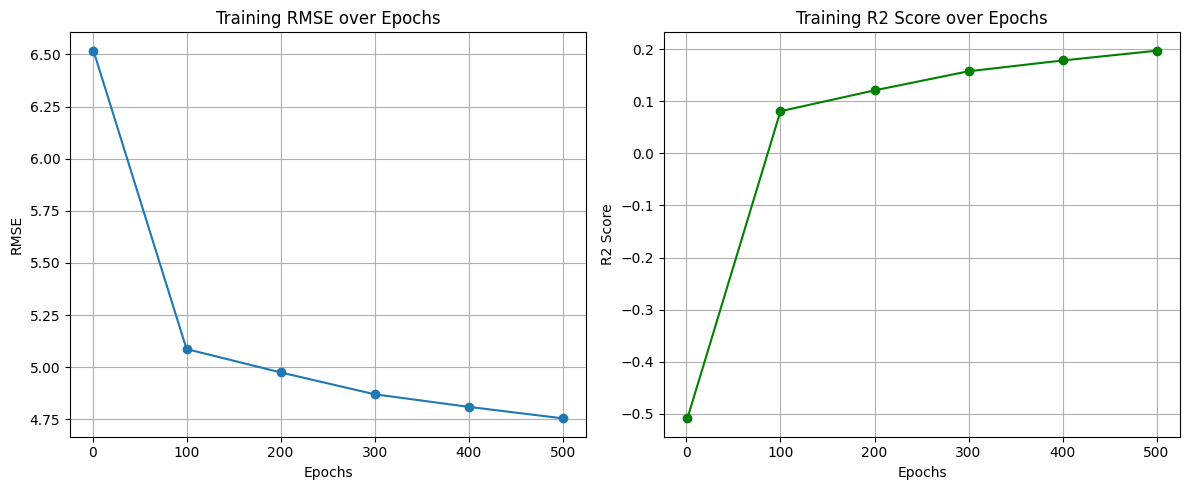

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, r2_score # Import r2_score
from sklearn.utils import resample

import numpy as np
import matplotlib.pyplot as plt # Import matplotlib for plotting
import time # Import the time module

# --- Data Loading and Preprocessing (ensuring 'language' column exists) ---
# Reload the dataset to ensure 'language' column is present for one-hot encoding
df = pd.read_csv("data_jurnal_infotel.csv")
df = df.drop(columns=["title", "DoI","status"])

# Filter out rows where 'language' is 'Indonesia'
df = df[df['language'] != 'Indonesia']

# Convert categorical columns to dummy variables (One-Hot Encoding)
df = pd.get_dummies(df, columns=["language"], drop_first=True)

# Separate features (X) and target variable (y - scholar_citation)
X = df.drop(columns=["scholar_citation"]).astype(float).values
y = df["scholar_citation"].astype(float).values.reshape(-1, 1)

# Normalize features (Min-Max Scaling) to prevent gradient explosion
X_min = X.min(axis=0)
X_max = X.max(axis=0)
# Avoid division by zero for constant columns
X_max[X_max == X_min] = 1.0
X = (X - X_min) / (X_max - X_min)

# Shuffle and Split into Train (80%) and Test (20%) sets
indices = np.arange(X.shape[0])
np.random.shuffle(indices)

split_idx = int(0.8 * len(indices))
train_idx, test_idx = indices[:split_idx], indices[split_idx:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]


# ==========================================
# 2. MLP FROM SCRATCH IMPLEMENTATION
# ==========================================

class MLPRegressorFromScratch:

    def __init__(self, input_dim, hidden_dim, learning_rate=0.01):
        self.lr = learning_rate

        # He (Kaiming) Initialization for weights, zeros for biases
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(
            2.0 / input_dim
        )
        self.b1 = np.zeros((1, hidden_dim))

        self.W2 = np.random.randn(hidden_dim, 1) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, 1))

        # Optimization history
        self.history = {'epochs': [], 'train_rmse': [], 'train_r2': []}

    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        return (Z > 0).astype(float)

    def forward(self, X):
        # Layer 1 (Hidden)
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self.relu(self.Z1)

        # Layer 2 (Output - Linear activation for regression)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        return self.Z2

    def backward(self, X, y, output):
        m = X.shape[0]

        # Output layer error (MSE derivative)
        dZ2 = 2 * (output - y) / m
        dW2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        # Hidden layer error
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * self.relu_derivative(self.Z1)
        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        # Update parameters using Gradient Descent
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def fit(self, X, y, epochs=1000, batch_size=32):
        m = X.shape[0]
        for epoch in range(epochs):
            # Shuffle every epoch for Stochastic/Mini-batch behavior
            permutation = np.random.permutation(m)
            X_shuffled = X[permutation]
            y_shuffled = y[permutation]

            for i in range(0, m, batch_size):
                X_batch = X_shuffled[i : i + batch_size]
                y_batch = y_shuffled[i : i + batch_size]

                predictions = self.forward(X_batch)
                self.backward(X_batch, y_batch, predictions)

            # Print loss and record history every 100 epochs or at epoch 0
            if (epoch + 1) % 100 == 0 or epoch == 0:
                full_pred = self.forward(X)
                rmse = np.sqrt(np.mean((full_pred - y) ** 2))
                r2 = r2_score(y, full_pred)
                self.history['epochs'].append(epoch + 1)
                self.history['train_rmse'].append(rmse)
                self.history['train_r2'].append(r2)
                print(f"Epoch {epoch+1}/{epochs} - Train RMSE: {rmse:.4f}, Train R2: {r2:.4f}")


# ==========================================
# 3. TRAINING AND EVALUATION
# ==========================================

# Initialize network dimensions
input_dimensions = X_train.shape[1]
hidden_neurons = 16  # You can tweak this architecture

# Create and train the model
mlp = MLPRegressorFromScratch(
    input_dim=input_dimensions, hidden_dim=hidden_neurons, learning_rate=0.001
)
print("Starting training...")
start_time = time.time()
mlp.fit(X_train, y_train, epochs=500, batch_size=16)
end_time = time.time()
training_time = end_time - start_time
print(f"Training complete in {training_time:.2f} seconds.")

# Evaluate on Test Data
test_predictions = mlp.forward(X_test)
test_rmse = np.sqrt(np.mean((test_predictions - y_test) ** 2))
test_mae = np.mean(np.abs(test_predictions - y_test))
test_r2 = r2_score(y_test, test_predictions)

print("\n--- Evaluation Results ---")
print(f"Test Root Mean Squared Error (RMSE): {test_rmse:.4f}")
print(f"Test Mean Absolute Error (MAE): {test_mae:.4f}")
print(f"Test R2 Score: {test_r2:.4f}")


# ==========================================
# 4. PLOT OPTIMIZATION HISTORY
# ==========================================

plt.figure(figsize=(12, 5))

# Plot Training RMSE
plt.subplot(1, 2, 1)
plt.plot(mlp.history['epochs'], mlp.history['train_rmse'], marker='o')
plt.title('Training RMSE over Epochs')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.grid(True)

# Plot Training R2 Score
plt.subplot(1, 2, 2)
plt.plot(mlp.history['epochs'], mlp.history['train_r2'], marker='o', color='green')
plt.title('Training R2 Score over Epochs')
plt.xlabel('Epochs')
plt.ylabel('R2 Score')
plt.grid(True)

plt.tight_layout()
plt.show()

# GA


--- Starting Genetic Algorithm for MLP Weight Optimization ---
Generation 1/20: Current Best in Gen (RMSE: 6.1912), Overall Best (RMSE: 6.1912), Avg Fitness = -6.8521
Generation 2/20: Current Best in Gen (RMSE: 6.1912), Overall Best (RMSE: 6.1912), Avg Fitness = -6.8361
Generation 3/20: Current Best in Gen (RMSE: 6.1912), Overall Best (RMSE: 6.1912), Avg Fitness = -6.8178
Generation 4/20: Current Best in Gen (RMSE: 6.1912), Overall Best (RMSE: 6.1912), Avg Fitness = -6.8152
Generation 5/20: Current Best in Gen (RMSE: 6.1905), Overall Best (RMSE: 6.1905), Avg Fitness = -6.7896
Generation 6/20: Current Best in Gen (RMSE: 6.1905), Overall Best (RMSE: 6.1905), Avg Fitness = -6.7970
Generation 7/20: Current Best in Gen (RMSE: 6.1905), Overall Best (RMSE: 6.1905), Avg Fitness = -6.8029
Generation 8/20: Current Best in Gen (RMSE: 6.1905), Overall Best (RMSE: 6.1905), Avg Fitness = -6.8032
Generation 9/20: Current Best in Gen (RMSE: 6.1889), Overall Best (RMSE: 6.1889), Avg Fitness = -6.7963


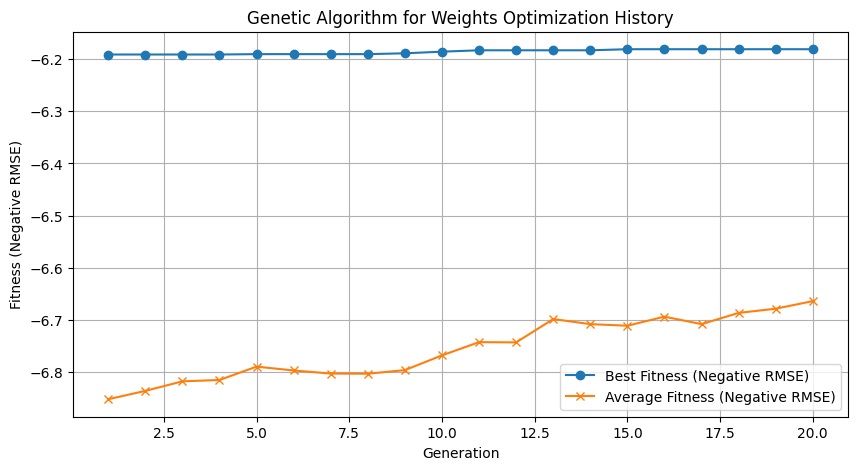


--- Evaluating final MLP with optimal weights found by GA ---

--- Final MLP Evaluation Results (Weights Optimized by GA) ---
Test Root Mean Squared Error (RMSE): 6.5052
Test Mean Absolute Error (MAE): 4.1809
Test R2 Score: -0.4934

--- Comprehensive Comparison of MLP Models ---
1. Original MLP (Backprop without optimization):
  Training Time: 0.77 seconds
  Test RMSE: 5.2151
  Test MAE: 3.8357
  Test R2 Score: 0.0402

4. GA-Optimized MLP (Weight Optimization):
  GA Weight Optimization Time: 1.24 seconds
  Test RMSE: 6.5052
  Test MAE: 4.1809
  Test R2 Score: -0.4934


In [ ]:
import random
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import time

# Ensure reproducibility
np.random.seed(randdss)

# --- MLPRegressorFromScratch class definition (if not already available) ---
# Assuming MLPRegressorFromScratch is defined in a previous cell (g3lyqVx9n2YK)
# and available in the kernel's global scope. If not, it would need to be re-defined here.

# ==========================================
# Genetic Algorithm for MLP Weight Optimization
# ==========================================

# GA Parameters for Weights
POPULATION_SIZE_WEIGHTS = 50
NUM_GENERATIONS_WEIGHTS = 20
MUTATION_RATE_WEIGHTS = 0.1 # Probability of a gene mutating
MUTATION_STRENGTH = 0.01 # Magnitude of mutation
CROSSOVER_RATE_WEIGHTS = 0.8 # Probability of crossover

# Fixed MLP architecture for GA-trained weights (using previous optimal or default)
# We'll use the hidden_neurons and input_dimensions from the original MLP setup.
mlp_input_dim = input_dimensions
mlp_hidden_dim = hidden_neurons # Using 16 as from the original MLP

def flatten_mlp_weights(mlp_instance):
    """Flattens all weights and biases into a single 1D array (chromosome)."""
    return np.concatenate([
        mlp_instance.W1.flatten(),
        mlp_instance.b1.flatten(),
        mlp_instance.W2.flatten(),
        mlp_instance.b2.flatten()
    ])

def unflatten_mlp_weights(chromosome, input_dim, hidden_dim):
    """Reconstructs weights and biases from a 1D array."""
    num_w1 = input_dim * hidden_dim
    num_b1 = hidden_dim
    num_w2 = hidden_dim * 1 # Output dim is 1
    num_b2 = 1

    W1_flat = chromosome[:num_w1]
    b1_flat = chromosome[num_w1 : num_w1 + num_b1]
    W2_flat = chromosome[num_w1 + num_b1 : num_w1 + num_b1 + num_w2]
    b2_flat = chromosome[num_w1 + num_b1 + num_w2 :]

    # Create a dummy MLP to hold these weights for reconstruction and evaluation
    temp_mlp = MLPRegressorFromScratch(input_dim=input_dim, hidden_dim=hidden_dim, learning_rate=0.001) # LR doesn't matter here
    temp_mlp.W1 = W1_flat.reshape(input_dim, hidden_dim)
    temp_mlp.b1 = b1_flat.reshape(1, hidden_dim)
    temp_mlp.W2 = W2_flat.reshape(hidden_dim, 1)
    temp_mlp.b2 = b2_flat.reshape(1, 1)
    return temp_mlp

def calculate_fitness_weights(chromosome, X_data, y_data, input_dim, hidden_dim):
    """Evaluates the fitness of a chromosome (set of weights)."""
    mlp = unflatten_mlp_weights(chromosome, input_dim, hidden_dim)
    predictions = mlp.forward(X_data)
    rmse = np.sqrt(mean_squared_error(y_data, predictions))
    return -rmse # GA maximizes, so we return negative RMSE

def create_initial_population(pop_size, input_dim, hidden_dim):
    """Creates a population of random MLP weight chromosomes."""
    population = []
    for _ in range(pop_size):
        # Initialize a new MLP to get random weights
        mlp = MLPRegressorFromScratch(input_dim=input_dim, hidden_dim=hidden_dim, learning_rate=0.001)
        chromosome = flatten_mlp_weights(mlp)
        population.append(chromosome)
    return population

def selection(population, fitnesses, num_parents):
    """Selects parents based on fitness (roulette wheel selection)."""
    total_fitness = sum(fitnesses)
    selection_probs = [f / total_fitness for f in fitnesses]
    # Ensure sum of probabilities is 1 for np.random.choice
    selection_probs /= np.sum(selection_probs)

    selected_indices = np.random.choice(len(population), size=num_parents, p=selection_probs, replace=False)
    return [population[i] for i in selected_indices]

def crossover(parent1, parent2, crossover_rate):
    """Performs arithmetic crossover on two parents."""
    if np.random.rand() < crossover_rate:
        alpha = np.random.rand()
        child1 = alpha * parent1 + (1 - alpha) * parent2
        child2 = alpha * parent2 + (1 - alpha) * parent1
        return child1, child2
    else:
        return parent1, parent2

def mutate(chromosome, mutation_rate, mutation_strength):
    """Applies Gaussian mutation to a chromosome."""
    mutated_chromosome = np.copy(chromosome)
    for i in range(len(mutated_chromosome)):
        if np.random.rand() < mutation_rate:
            mutated_chromosome[i] += np.random.normal(0, mutation_strength)
    return mutated_chromosome

# --- Run the Genetic Algorithm for Weight Optimization ---
print("\n--- Starting Genetic Algorithm for MLP Weight Optimization ---")
ga_weights_start_time = time.time()

# 1. Initialize population
population = create_initial_population(POPULATION_SIZE_WEIGHTS, mlp_input_dim, mlp_hidden_dim)

best_ga_weights_chromosome = None
best_ga_weights_fitness = -np.inf
ga_weights_history = {'generation': [], 'best_fitness': [], 'avg_fitness': []}

for generation in range(NUM_GENERATIONS_WEIGHTS):
    # 2. Evaluate fitness for each individual
    fitnesses = [calculate_fitness_weights(chrom, X_train, y_train, mlp_input_dim, mlp_hidden_dim) for chrom in population]

    current_best_gen_idx = np.argmax(fitnesses)
    current_best_gen_fitness = fitnesses[current_best_gen_idx]

    if current_best_gen_fitness > best_ga_weights_fitness:
        best_ga_weights_fitness = current_best_gen_fitness
        best_ga_weights_chromosome = population[current_best_gen_idx]

    avg_fitness = np.mean(fitnesses)
    ga_weights_history['generation'].append(generation + 1)
    ga_weights_history['best_fitness'].append(best_ga_weights_fitness) # Overall best
    ga_weights_history['avg_fitness'].append(avg_fitness)

    print(f"Generation {generation+1}/{NUM_GENERATIONS_WEIGHTS}: Current Best in Gen (RMSE: {-current_best_gen_fitness:.4f}), Overall Best (RMSE: {-best_ga_weights_fitness:.4f}), Avg Fitness = {avg_fitness:.4f}")

    # 3. Selection (Elitism + Roulette Wheel)
    # Keep the best individual directly
    new_population = [best_ga_weights_chromosome]

    # Select remaining parents using roulette wheel
    parents = selection(population, [f - min(fitnesses) + 1e-6 for f in fitnesses], POPULATION_SIZE_WEIGHTS - 1) # Shift fitness to be positive

    # 4. Crossover and Mutation to create next generation
    while len(new_population) < POPULATION_SIZE_WEIGHTS:
        p1, p2 = random.sample(parents, 2)
        child1, child2 = crossover(p1, p2, CROSSOVER_RATE_WEIGHTS)
        new_population.append(mutate(child1, MUTATION_RATE_WEIGHTS, MUTATION_STRENGTH))
        if len(new_population) < POPULATION_SIZE_WEIGHTS:
            new_population.append(mutate(child2, MUTATION_RATE_WEIGHTS, MUTATION_STRENGTH))

    population = new_population

ga_weights_end_time = time.time()
ga_weights_training_time = ga_weights_end_time - ga_weights_start_time
print(f"--- Genetic Algorithm for Weights Finished in {ga_weights_training_time:.2f} seconds ---")

# Plot the GA's optimization history for weights
plt.figure(figsize=(10, 5))
plt.plot(ga_weights_history['generation'], ga_weights_history['best_fitness'], label='Best Fitness (Negative RMSE)', marker='o')
plt.plot(ga_weights_history['generation'], ga_weights_history['avg_fitness'], label='Average Fitness (Negative RMSE)', marker='x')
plt.xlabel('Generation')
plt.ylabel('Fitness (Negative RMSE)')
plt.title('Genetic Algorithm for Weights Optimization History')
plt.legend()
plt.grid(True)
plt.show()

# --- Train the final MLP model using the optimal weights found by GA ---
print("\n--- Evaluating final MLP with optimal weights found by GA ---")
final_ga_weights_mlp = unflatten_mlp_weights(best_ga_weights_chromosome, mlp_input_dim, mlp_hidden_dim)

# Evaluate the final GA-weighted MLP model on the test set
final_ga_weights_predictions = final_ga_weights_mlp.forward(X_test)
final_ga_weights_test_rmse = np.sqrt(mean_squared_error(y_test, final_ga_weights_predictions))
final_ga_weights_test_mae = np.mean(np.abs(final_ga_weights_predictions - y_test))
final_ga_weights_test_r2 = r2_score(y_test, final_ga_weights_predictions)

print("\n--- Final MLP Evaluation Results (Weights Optimized by GA) ---")
print(f"Test Root Mean Squared Error (RMSE): {final_ga_weights_test_rmse:.4f}")
print(f"Test Mean Absolute Error (MAE): {final_ga_weights_test_mae:.4f}")
print(f"Test R2 Score: {final_ga_weights_test_r2:.4f}")

# ==========================================
# Comparison of all MLP Models
# ==========================================

print("\n--- Comprehensive Comparison of MLP Models ---")
print("1. Original MLP (Backprop without optimization):")
print(f"  Training Time: {training_time:.2f} seconds")
print(f"  Test RMSE: {test_rmse:.4f}")
print(f"  Test MAE: {test_mae:.4f}")
print(f"  Test R2 Score: {test_r2:.4f}")



print("\n4. GA-Optimized MLP (Weight Optimization):")
print(f"  GA Weight Optimization Time: {ga_weights_training_time:.2f} seconds")
print(f"  Test RMSE: {final_ga_weights_test_rmse:.4f}")
print(f"  Test MAE: {final_ga_weights_test_mae:.4f}")
print(f"  Test R2 Score: {final_ga_weights_test_r2:.4f}")

# PSO


--- Starting Particle Swarm Optimization for MLP Weight Optimization ---
Iteration 1/20: Global Best (RMSE: 6.1615), Avg Fitness = -6.8372
Iteration 2/20: Global Best (RMSE: 6.0657), Avg Fitness = -6.7514
Iteration 3/20: Global Best (RMSE: 6.0001), Avg Fitness = -6.6417
Iteration 4/20: Global Best (RMSE: 5.9282), Avg Fitness = -6.5001
Iteration 5/20: Global Best (RMSE: 5.8124), Avg Fitness = -6.3414
Iteration 6/20: Global Best (RMSE: 5.7012), Avg Fitness = -6.1494
Iteration 7/20: Global Best (RMSE: 5.5933), Avg Fitness = -5.9472
Iteration 8/20: Global Best (RMSE: 5.5143), Avg Fitness = -5.7459
Iteration 9/20: Global Best (RMSE: 5.4645), Avg Fitness = -5.5849
Iteration 10/20: Global Best (RMSE: 5.4225), Avg Fitness = -5.4886
Iteration 11/20: Global Best (RMSE: 5.3887), Avg Fitness = -5.4438
Iteration 12/20: Global Best (RMSE: 5.3768), Avg Fitness = -5.4398
Iteration 13/20: Global Best (RMSE: 5.3571), Avg Fitness = -5.4452
Iteration 14/20: Global Best (RMSE: 5.3571), Avg Fitness = -5.42

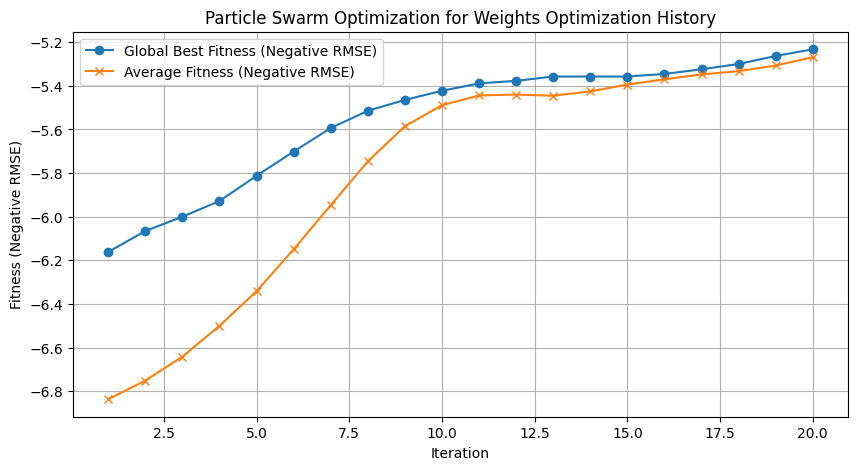


--- Evaluating final MLP with optimal weights found by PSO ---

--- Final MLP Evaluation Results (Weights Optimized by PSO) ---
Test Root Mean Squared Error (RMSE): 5.3239
Test Mean Absolute Error (MAE): 3.9735
Test R2 Score: -0.0003

--- Comprehensive Comparison of MLP Models ---

1. Original MLP (Backprop without optimization):
  Training Time: 0.77 seconds
  Test RMSE: 5.2151
  Test MAE: 3.8357
  Test R2 Score: 0.0402

4. GA-Optimized MLP (Weight Optimization):
  GA Weight Optimization Time: 1.24 seconds
  Test RMSE: 6.5052
  Test MAE: 4.1809
  Test R2 Score: -0.4934

5. PSO-Optimized MLP (Weight Optimization):
  PSO Weight Optimization Time: 1.50 seconds
  Test RMSE: 5.3239
  Test MAE: 3.9735
  Test R2 Score: -0.0003



In [ ]:
import random
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import time

# Ensure reproducibility
np.random.seed(randdss)

# --- MLPRegressorFromScratch class definition (if not already available) ---
# Assuming MLPRegressorFromScratch is defined in a previous cell (g3lyqVx9n2YK)
# and available in the kernel's global scope.

# --- Helper functions for flattening/unflattening weights (copied for this cell) ---
def flatten_mlp_weights(mlp_instance):
    """Flattens all weights and biases into a single 1D array (chromosome)."""
    return np.concatenate([
        mlp_instance.W1.flatten(),
        mlp_instance.b1.flatten(),
        mlp_instance.W2.flatten(),
        mlp_instance.b2.flatten()
    ])

def unflatten_mlp_weights(chromosome, input_dim, hidden_dim):
    """Reconstructs weights and biases from a 1D array."""
    num_w1 = input_dim * hidden_dim
    num_b1 = hidden_dim
    num_w2 = hidden_dim * 1 # Output dim is 1
    num_b2 = 1

    W1_flat = chromosome[:num_w1]
    b1_flat = chromosome[num_w1 : num_w1 + num_b1]
    W2_flat = chromosome[num_w1 + num_b1 : num_w1 + num_b1 + num_w2]
    b2_flat = chromosome[num_w1 + num_b1 + num_w2 :]

    # Create a dummy MLP to hold these weights for reconstruction and evaluation
    temp_mlp = MLPRegressorFromScratch(input_dim=input_dim, hidden_dim=hidden_dim, learning_rate=0.001) # LR doesn't matter here
    temp_mlp.W1 = W1_flat.reshape(input_dim, hidden_dim)
    temp_mlp.b1 = b1_flat.reshape(1, hidden_dim)
    temp_mlp.W2 = W2_flat.reshape(hidden_dim, 1)
    temp_mlp.b2 = b2_flat.reshape(1, 1)
    return temp_mlp

def pso_weights_fitness(chromosome, X_data, y_data, input_dim, hidden_dim):
    """Evaluates the fitness of a chromosome (set of weights) for PSO."""
    mlp = unflatten_mlp_weights(chromosome, input_dim, hidden_dim)
    predictions = mlp.forward(X_data)
    rmse = np.sqrt(mean_squared_error(y_data, predictions))
    return -rmse # PSO minimizes by default, so we return negative RMSE for maximization

# ==========================================
# Particle Swarm Optimization (PSO) for MLP Weight Optimization
# ==========================================

# PSO Parameters for Weights
NUM_PARTICLES_WEIGHTS_PSO = 50
NUM_ITERATIONS_WEIGHTS_PSO = 20
W_WEIGHTS_PSO = 0.7       # Inertia weight
C1_WEIGHTS_PSO = 1.5      # Cognitive coefficient (personal best)
C2_WEIGHTS_PSO = 1.5      # Social coefficient (global best)
VELOCITY_CLAMP = 0.1      # Max change allowed for a weight in one step

# Fixed MLP architecture for PSO-trained weights
# Using the hidden_neurons and input_dimensions from the original MLP setup.
mlp_input_dim_pso = input_dimensions
mlp_hidden_dim_pso = hidden_neurons # Using 16 as from the original MLP

# --- Run the Particle Swarm Optimization for Weight Optimization ---
print("\n--- Starting Particle Swarm Optimization for MLP Weight Optimization ---")
pso_weights_start_time = time.time()

# Get initial weight vector size
dummy_mlp = MLPRegressorFromScratch(input_dim=mlp_input_dim_pso, hidden_dim=mlp_hidden_dim_pso, learning_rate=0.001)
weight_vector_size = len(flatten_mlp_weights(dummy_mlp))

# Initialize particles
particles = [] # Each particle: [current_pos, velocity, pbest_pos, pbest_fitness]
gbest_position_weights = None
gbest_fitness_weights = -np.inf # Initialize with negative infinity for maximization

pso_weights_history = {'iteration': [], 'gbest_fitness': [], 'avg_fitness': []}

for i in range(NUM_PARTICLES_WEIGHTS_PSO):
    # Random initial position (weights)
    init_pos = flatten_mlp_weights(MLPRegressorFromScratch(input_dim=mlp_input_dim_pso, hidden_dim=mlp_hidden_dim_pso, learning_rate=0.001))
    # Random initial velocity
    init_vel = np.random.uniform(-VELOCITY_CLAMP, VELOCITY_CLAMP, weight_vector_size)

    init_fitness = pso_weights_fitness(init_pos, X_train, y_train, mlp_input_dim_pso, mlp_hidden_dim_pso)

    particles.append({
        'position': init_pos,
        'velocity': init_vel,
        'pbest_position': init_pos,
        'pbest_fitness': init_fitness
    })

    if init_fitness > gbest_fitness_weights:
        gbest_fitness_weights = init_fitness
        gbest_position_weights = init_pos

for iteration in range(NUM_ITERATIONS_WEIGHTS_PSO):
    current_iteration_fitnesses = []
    for particle in particles:
        r1 = np.random.rand(weight_vector_size)
        r2 = np.random.rand(weight_vector_size)

        # Update velocity
        particle['velocity'] = (W_WEIGHTS_PSO * particle['velocity'] +
                                C1_WEIGHTS_PSO * r1 * (particle['pbest_position'] - particle['position']) +
                                C2_WEIGHTS_PSO * r2 * (gbest_position_weights - particle['position']))

        # Clamp velocity to prevent explosion
        particle['velocity'] = np.clip(particle['velocity'], -VELOCITY_CLAMP, VELOCITY_CLAMP)

        # Update position
        particle['position'] += particle['velocity']

        # Evaluate current fitness
        current_fitness = pso_weights_fitness(particle['position'], X_train, y_train, mlp_input_dim_pso, mlp_hidden_dim_pso)
        current_iteration_fitnesses.append(current_fitness)

        # Update personal best
        if current_fitness > particle['pbest_fitness']:
            particle['pbest_fitness'] = current_fitness
            particle['pbest_position'] = particle['position'].copy()

        # Update global best
        if current_fitness > gbest_fitness_weights:
            gbest_fitness_weights = current_fitness
            gbest_position_weights = particle['position'].copy()

    avg_fitness_iter = np.mean(current_iteration_fitnesses)
    pso_weights_history['iteration'].append(iteration + 1)
    pso_weights_history['gbest_fitness'].append(gbest_fitness_weights) # Overall best
    pso_weights_history['avg_fitness'].append(avg_fitness_iter)

    print(f"Iteration {iteration+1}/{NUM_ITERATIONS_WEIGHTS_PSO}: Global Best (RMSE: {-gbest_fitness_weights:.4f}), Avg Fitness = {avg_fitness_iter:.4f}")

pso_weights_end_time = time.time()
pso_weights_training_time = pso_weights_end_time - pso_weights_start_time
print(f"--- Particle Swarm Optimization for Weights Finished in {pso_weights_training_time:.2f} seconds ---")

# Plot the PSO's optimization history for weights
plt.figure(figsize=(10, 5))
plt.plot(pso_weights_history['iteration'], pso_weights_history['gbest_fitness'], label='Global Best Fitness (Negative RMSE)', marker='o')
plt.plot(pso_weights_history['iteration'], pso_weights_history['avg_fitness'], label='Average Fitness (Negative RMSE)', marker='x')
plt.xlabel('Iteration')
plt.ylabel('Fitness (Negative RMSE)')
plt.title('Particle Swarm Optimization for Weights Optimization History')
plt.legend()
plt.grid(True)
plt.show()

# --- Evaluate the final MLP model using the optimal weights found by PSO ---
print("\n--- Evaluating final MLP with optimal weights found by PSO ---")
final_pso_weights_mlp = unflatten_mlp_weights(gbest_position_weights, mlp_input_dim_pso, mlp_hidden_dim_pso)

# Evaluate the final PSO-weighted MLP model on the test set
final_pso_weights_predictions = final_pso_weights_mlp.forward(X_test)
final_pso_weights_test_rmse = np.sqrt(mean_squared_error(y_test, final_pso_weights_predictions))
final_pso_weights_test_mae = np.mean(np.abs(final_pso_weights_predictions - y_test))
final_pso_weights_test_r2 = r2_score(y_test, final_pso_weights_predictions)

print("\n--- Final MLP Evaluation Results (Weights Optimized by PSO) ---")
print(f"Test Root Mean Squared Error (RMSE): {final_pso_weights_test_rmse:.4f}")
print(f"Test Mean Absolute Error (MAE): {final_pso_weights_test_mae:.4f}")
print(f"Test R2 Score: {final_pso_weights_test_r2:.4f}")

# ==========================================
# Comprehensive Comparison of all MLP Models
# ==========================================

print("\n--- Comprehensive Comparison of MLP Models ---\n")

print("1. Original MLP (Backprop without optimization):")
print(f"  Training Time: {training_time:.2f} seconds")
print(f"  Test RMSE: {test_rmse:.4f}")
print(f"  Test MAE: {test_mae:.4f}")
print(f"  Test R2 Score: {test_r2:.4f}\n")


# GA Weight Optimization results
print("4. GA-Optimized MLP (Weight Optimization):")
print(f"  GA Weight Optimization Time: {ga_weights_training_time:.2f} seconds")
print(f"  Test RMSE: {final_ga_weights_test_rmse:.4f}")
print(f"  Test MAE: {final_ga_weights_test_mae:.4f}")
print(f"  Test R2 Score: {final_ga_weights_test_r2:.4f}\n")

# New PSO Weight Optimization results
print("5. PSO-Optimized MLP (Weight Optimization):")
print(f"  PSO Weight Optimization Time: {pso_weights_training_time:.2f} seconds")
print(f"  Test RMSE: {final_pso_weights_test_rmse:.4f}")
print(f"  Test MAE: {final_pso_weights_test_mae:.4f}")
print(f"  Test R2 Score: {final_pso_weights_test_r2:.4f}\n")

# TLBO


--- Starting Teaching-Learning-Based Optimization for MLP Weight Optimization ---
Iteration 1/20: Best in Gen RMSE: 6.3531, Overall Best RMSE: 6.3531, Avg RMSE = 6.8200
Iteration 2/20: Best in Gen RMSE: 5.5260, Overall Best RMSE: 5.5260, Avg RMSE = 6.2705
Iteration 3/20: Best in Gen RMSE: 5.4893, Overall Best RMSE: 5.4893, Avg RMSE = 5.9568
Iteration 4/20: Best in Gen RMSE: 5.3059, Overall Best RMSE: 5.3059, Avg RMSE = 5.7740
Iteration 5/20: Best in Gen RMSE: 5.3056, Overall Best RMSE: 5.3056, Avg RMSE = 5.6716
Iteration 6/20: Best in Gen RMSE: 5.2109, Overall Best RMSE: 5.2109, Avg RMSE = 5.5519
Iteration 7/20: Best in Gen RMSE: 5.2109, Overall Best RMSE: 5.2109, Avg RMSE = 5.5092
Iteration 8/20: Best in Gen RMSE: 5.2109, Overall Best RMSE: 5.2109, Avg RMSE = 5.4765
Iteration 9/20: Best in Gen RMSE: 5.2109, Overall Best RMSE: 5.2109, Avg RMSE = 5.4524
Iteration 10/20: Best in Gen RMSE: 5.2109, Overall Best RMSE: 5.2109, Avg RMSE = 5.4245
Iteration 11/20: Best in Gen RMSE: 5.2109, Ove

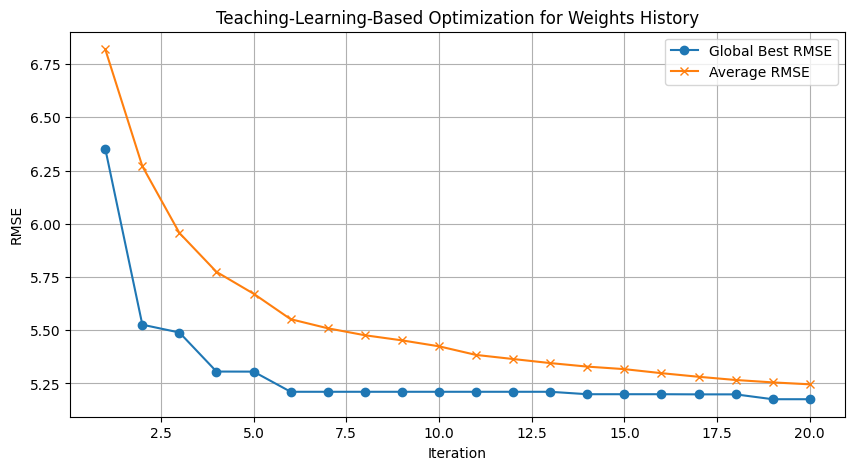


--- Evaluating final MLP with optimal weights found by TLBO ---

--- Final MLP Evaluation Results (Weights Optimized by TLBO) ---
Test Root Mean Squared Error (RMSE): 5.5070
Test Mean Absolute Error (MAE): 3.9900
Test R2 Score: -0.0702

--- Comprehensive Comparison of MLP Models ---

1. Original MLP (Backprop without optimization):
  Training Time: 0.77 seconds
  Test RMSE: 5.2151
  Test MAE: 3.8357
  Test R2 Score: 0.0402

2. GA-Optimized MLP (Weight Optimization):
  GA Weight Optimization Time: 1.24 seconds
  Test RMSE: 6.5052
  Test MAE: 4.1809
  Test R2 Score: -0.4934

3. PSO-Optimized MLP (Weight Optimization):
  PSO Weight Optimization Time: 1.50 seconds
  Test RMSE: 5.3239
  Test MAE: 3.9735
  Test R2 Score: -0.0003

4. TLBO-Optimized MLP (Weight Optimization):
  TLBO Weight Optimization Time: 2.91 seconds
  Test RMSE: 5.5070
  Test MAE: 3.9900
  Test R2 Score: -0.0702



In [ ]:
import random
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import time

# Ensure reproducibility
np.random.seed(randdss)

# --- MLPRegressorFromScratch class definition (assuming it's globally available) ---
# The MLPRegressorFromScratch class should be defined in a previous cell (e.g., g3lyqVx9n2YK).

# --- Helper functions for flattening/unflattening weights (copied for this cell) ---
def flatten_mlp_weights(mlp_instance):
    """Flattens all weights and biases into a single 1D array (chromosome)."""
    return np.concatenate([
        mlp_instance.W1.flatten(),
        mlp_instance.b1.flatten(),
        mlp_instance.W2.flatten(),
        mlp_instance.b2.flatten()
    ])

def unflatten_mlp_weights(chromosome, input_dim, hidden_dim):
    """Reconstructs weights and biases from a 1D array."""
    num_w1 = input_dim * hidden_dim
    num_b1 = hidden_dim
    num_w2 = hidden_dim * 1 # Output dim is 1
    num_b2 = 1

    W1_flat = chromosome[:num_w1]
    b1_flat = chromosome[num_w1 : num_w1 + num_b1]
    W2_flat = chromosome[num_w1 + num_b1 : num_w1 + num_b1 + num_w2]
    b2_flat = chromosome[num_w1 + num_b1 + num_w2 :]

    # Create a dummy MLP to hold these weights for reconstruction and evaluation
    temp_mlp = MLPRegressorFromScratch(input_dim=input_dim, hidden_dim=hidden_dim, learning_rate=0.001) # LR doesn't matter here
    temp_mlp.W1 = W1_flat.reshape(input_dim, hidden_dim)
    temp_mlp.b1 = b1_flat.reshape(1, hidden_dim)
    temp_mlp.W2 = W2_flat.reshape(hidden_dim, 1)
    temp_mlp.b2 = b2_flat.reshape(1, 1)
    return temp_mlp

def tlbo_weights_fitness(chromosome, X_data, y_data, input_dim, hidden_dim):
    """Evaluates the fitness of a chromosome (set of weights) for TLBO.
    Returns negative RMSE because TLBO aims to minimize, and we want to maximize fitness."""
    mlp = unflatten_mlp_weights(chromosome, input_dim, hidden_dim)
    predictions = mlp.forward(X_data)
    rmse = np.sqrt(mean_squared_error(y_data, predictions))
    return rmse # TLBO typically minimizes, so we return RMSE directly

# ==========================================
# Teaching-Learning-Based Optimization (TLBO) for MLP Weight Optimization
# ==========================================

# TLBO Parameters
NUM_STUDENTS_TLBO = 50
NUM_ITERATIONS_TLBO = 20
WEIGHT_LOWER_BOUND = -5.0 # Example lower bound for weights/biases
WEIGHT_UPPER_BOUND = 5.0  # Example upper bound for weights/biases

# Fixed MLP architecture for TLBO-trained weights
# Using the hidden_neurons and input_dimensions from the original MLP setup.
mlp_input_dim_tlbo = input_dimensions
mlp_hidden_dim_tlbo = hidden_neurons # Using 16 as from the original MLP

class Student:
    def __init__(self, position, fitness):
        self.position = position
        self.fitness = fitness

# --- Run the TLBO for Weight Optimization ---
print("\n--- Starting Teaching-Learning-Based Optimization for MLP Weight Optimization ---")
tlbo_weights_start_time = time.time()

# Get initial weight vector size
dummy_mlp = MLPRegressorFromScratch(input_dim=mlp_input_dim_tlbo, hidden_dim=mlp_hidden_dim_tlbo, learning_rate=0.001)
weight_vector_size = len(flatten_mlp_weights(dummy_mlp))

# Step 1: Randomly initialize Class of N students Xi (i=1, 2, …, N)
student_class = []
for _ in range(NUM_STUDENTS_TLBO):
    initial_mlp = MLPRegressorFromScratch(input_dim=mlp_input_dim_tlbo, hidden_dim=mlp_hidden_dim_tlbo, learning_rate=0.001)
    position = flatten_mlp_weights(initial_mlp)
    # Clip initial positions to ensure they are within bounds
    position = np.clip(position, WEIGHT_LOWER_BOUND, WEIGHT_UPPER_BOUND)
    fitness = tlbo_weights_fitness(position, X_train, y_train, mlp_input_dim_tlbo, mlp_hidden_dim_tlbo)
    student_class.append(Student(position, fitness))

# Track history
tlbo_weights_history = {'iteration': [], 'best_rmse': [], 'avg_rmse': []}

best_overall_rmse = np.inf
best_overall_position = None

# Step 3: For Iter in range(max_iter):
for iteration in range(NUM_ITERATIONS_TLBO):
    current_iteration_rmses = []
    for student in student_class:
        current_iteration_rmses.append(student.fitness)

    # Update overall best RMSE and position
    current_best_in_gen_idx = np.argmin(current_iteration_rmses)
    current_best_in_gen_rmse = current_iteration_rmses[current_best_in_gen_idx]
    if current_best_in_gen_rmse < best_overall_rmse:
        best_overall_rmse = current_best_in_gen_rmse
        best_overall_position = student_class[current_best_in_gen_idx].position.copy()

    avg_rmse_iter = np.mean(current_iteration_rmses)
    tlbo_weights_history['iteration'].append(iteration + 1)
    tlbo_weights_history['best_rmse'].append(best_overall_rmse)
    tlbo_weights_history['avg_rmse'].append(avg_rmse_iter)

    print(f"Iteration {iteration+1}/{NUM_ITERATIONS_TLBO}: Best in Gen RMSE: {current_best_in_gen_rmse:.4f}, Overall Best RMSE: {best_overall_rmse:.4f}, Avg RMSE = {avg_rmse_iter:.4f}")

    # Iterate for each student
    for i in range(len(student_class)):
        current_student = student_class[i]

        # Teaching phase-----------
        # Xteacher = student with least fitness value (lowest RMSE)
        teacher = min(student_class, key=lambda s: s.fitness)

        # Xmean = mean of all the students
        mean_position = np.mean([s.position for s in student_class], axis=0)

        # TF (teaching factor) = either 1 or 2 (randomly chosen)
        TF = random.choice([1, 2])
        r = np.random.rand(weight_vector_size) # Random number [0,1]

        Xnew_teaching = current_student.position + r * (teacher.position - TF * mean_position)

        # if Xnew < minx OR Xnew > maxx then clip it
        Xnew_teaching = np.clip(Xnew_teaching, WEIGHT_LOWER_BOUND, WEIGHT_UPPER_BOUND)

        # compute fitness of new solution
        fnew_teaching = tlbo_weights_fitness(Xnew_teaching, X_train, y_train, mlp_input_dim_tlbo, mlp_hidden_dim_tlbo)

        # greedy selection strategy
        if fnew_teaching < current_student.fitness:
            current_student.position = Xnew_teaching
            current_student.fitness = fnew_teaching

        # Learning phase------------
        # Xpartner = randomly chosen student from class (excluding current_student)
        partner_idx = random.randint(0, len(student_class) - 1)
        while partner_idx == i:
            partner_idx = random.randint(0, len(student_class) - 1)
        Xpartner = student_class[partner_idx]

        r_learning = np.random.rand(weight_vector_size) # Random number [0,1]

        Xnew_learning = np.array([]) # Initialize as empty array
        if current_student.fitness < Xpartner.fitness:
            Xnew_learning = current_student.position + r_learning * (current_student.position - Xpartner.position)
        else:
            Xnew_learning = current_student.position - r_learning * (current_student.position - Xpartner.position)

        # if Xnew < minx OR Xnew > maxx then clip it
        Xnew_learning = np.clip(Xnew_learning, WEIGHT_LOWER_BOUND, WEIGHT_UPPER_BOUND)

        # compute fitness of new solution
        fnew_learning = tlbo_weights_fitness(Xnew_learning, X_train, y_train, mlp_input_dim_tlbo, mlp_hidden_dim_tlbo)

        # greedy selection strategy
        if fnew_learning < current_student.fitness:
            current_student.position = Xnew_learning
            current_student.fitness = fnew_learning

tlbo_weights_end_time = time.time()
tlbo_weights_training_time = tlbo_weights_end_time - tlbo_weights_start_time
print(f"--- TLBO for Weights Finished in {tlbo_weights_training_time:.2f} seconds ---")

# Plot the TLBO's optimization history for weights
plt.figure(figsize=(10, 5))
plt.plot(tlbo_weights_history['iteration'], tlbo_weights_history['best_rmse'], label='Global Best RMSE', marker='o')
plt.plot(tlbo_weights_history['iteration'], tlbo_weights_history['avg_rmse'], label='Average RMSE', marker='x')
plt.xlabel('Iteration')
plt.ylabel('RMSE')
plt.title('Teaching-Learning-Based Optimization for Weights History')
plt.legend()
plt.grid(True)
plt.show()

# --- Evaluate the final MLP model using the optimal weights found by TLBO ---
print("\n--- Evaluating final MLP with optimal weights found by TLBO ---")
final_tlbo_weights_mlp = unflatten_mlp_weights(best_overall_position, mlp_input_dim_tlbo, mlp_hidden_dim_tlbo)

# Evaluate the final TLBO-weighted MLP model on the test set
final_tlbo_weights_predictions = final_tlbo_weights_mlp.forward(X_test)
final_tlbo_weights_test_rmse = np.sqrt(mean_squared_error(y_test, final_tlbo_weights_predictions))
final_tlbo_weights_test_mae = np.mean(np.abs(final_tlbo_weights_predictions - y_test))
final_tlbo_weights_test_r2 = r2_score(y_test, final_tlbo_weights_predictions)

print("\n--- Final MLP Evaluation Results (Weights Optimized by TLBO) ---")
print(f"Test Root Mean Squared Error (RMSE): {final_tlbo_weights_test_rmse:.4f}")
print(f"Test Mean Absolute Error (MAE): {final_tlbo_weights_test_mae:.4f}")
print(f"Test R2 Score: {final_tlbo_weights_test_r2:.4f}")

# ==========================================
# Comprehensive Comparison of all MLP Models
# ==========================================

print("\n--- Comprehensive Comparison of MLP Models ---\n")

print("1. Original MLP (Backprop without optimization):")
print(f"  Training Time: {training_time:.2f} seconds")
print(f"  Test RMSE: {test_rmse:.4f}")
print(f"  Test MAE: {test_mae:.4f}")
print(f"  Test R2 Score: {test_r2:.4f}\n")

print("2. GA-Optimized MLP (Weight Optimization):")
print(f"  GA Weight Optimization Time: {ga_weights_training_time:.2f} seconds")
print(f"  Test RMSE: {final_ga_weights_test_rmse:.4f}")
print(f"  Test MAE: {final_ga_weights_test_mae:.4f}")
print(f"  Test R2 Score: {final_ga_weights_test_r2:.4f}\n")

print("3. PSO-Optimized MLP (Weight Optimization):")
print(f"  PSO Weight Optimization Time: {pso_weights_training_time:.2f} seconds")
print(f"  Test RMSE: {final_pso_weights_test_rmse:.4f}")
print(f"  Test MAE: {final_pso_weights_test_mae:.4f}")
print(f"  Test R2 Score: {final_pso_weights_test_r2:.4f}\n")

# New TLBO Weight Optimization results
print("4. TLBO-Optimized MLP (Weight Optimization):")
print(f"  TLBO Weight Optimization Time: {tlbo_weights_training_time:.2f} seconds")
print(f"  Test RMSE: {final_tlbo_weights_test_rmse:.4f}")
print(f"  Test MAE: {final_tlbo_weights_test_mae:.4f}")
print(f"  Test R2 Score: {final_tlbo_weights_test_r2:.4f}\n")